# Задача 4. Інференційна статистика

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from statsmodels.stats.diagnostic import lilliefors

rng = np.random.default_rng(42)
df = pd.read_csv("app_metrics.csv")

## Частина 1. ЗВЧ та ЦГТ для Γ(2, 5)

     n    mean     var
     5 11.4887  9.8766
    25  8.8904 21.9646
   125 10.0977 63.1213
   625  9.8312 45.6900
  3125 10.1207 49.7607
 15625 10.0576 51.6960
 78125  9.9967 50.4331
390625  9.9963 49.7777


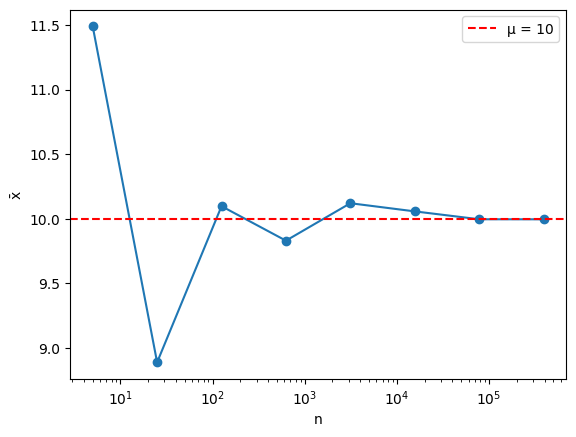

In [2]:
k, theta = 2, 5
mu, sigma = k * theta, np.sqrt(k * theta**2)
ns = 5 ** np.arange(1, 9)
samples = [rng.gamma(k, theta, n) for n in ns]
means = np.array([x.mean() for x in samples])
vars_ = np.array([x.var(ddof=1) for x in samples])
print(pd.DataFrame({"n": ns, "mean": means.round(4), "var": vars_.round(4)}).to_string(index=False))

plt.plot(ns, means, "o-")
plt.axhline(mu, color="r", ls="--", label="μ = 10")
plt.xscale("log")
plt.xlabel("n"); plt.ylabel("x̄"); plt.legend()
plt.show()

(а) При малих n вибіркове середнє помітно відхиляється від μ = 10 (11.49 при n=5, 8.89 при n=25), але зі зростанням n траєкторія стабілізується біля 10 (9.996 при n=390625). Це ілюструє слабкий ЗВЧ: $\bar X_n \xrightarrow{P} \mu$, тобто $P(|\bar X_n-\mu|>\varepsilon)\to 0$ для будь-якого ε > 0. Вибіркова дисперсія аналогічно наближається до σ² = 50.

     n   mean  low_σ  high_σ  low_s  high_s
     5 11.489  5.291  17.687  7.587  15.391
    25  8.890  6.119  11.662  6.956  10.825
   125 10.098  8.858  11.337  8.691  11.504
   625  9.831  9.277  10.386  9.300  10.362
  3125 10.121  9.873  10.369  9.873  10.368
 15625 10.058  9.947  10.169  9.945  10.170
 78125  9.997  9.947  10.046  9.947  10.046
390625  9.996  9.974  10.019  9.974  10.018


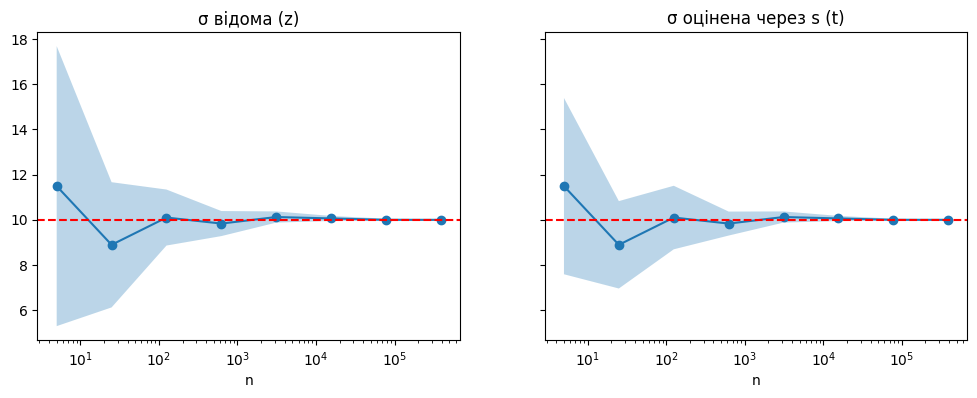

In [3]:
s = np.sqrt(vars_)
z = stats.norm.ppf(0.975)
t = stats.t.ppf(0.975, ns - 1)
ci_sigma = z * sigma / np.sqrt(ns)
ci_s = t * s / np.sqrt(ns)
print(pd.DataFrame({"n": ns, "mean": means, "low_σ": means - ci_sigma, "high_σ": means + ci_sigma,
                    "low_s": means - ci_s, "high_s": means + ci_s}).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, h, title in zip(ax, [ci_sigma, ci_s], ["σ відома (z)", "σ оцінена через s (t)"]):
    a.plot(ns, means, "o-")
    a.fill_between(ns, means - h, means + h, alpha=0.3)
    a.axhline(mu, color="r", ls="--")
    a.set_xscale("log"); a.set_title(title); a.set_xlabel("n")
plt.show()

(б) При відомій σ: $\bar x \pm z_{0.975}\frac{\sigma}{\sqrt n}$; при невідомій: $\bar x \pm t_{0.975,\,n-1}\frac{s}{\sqrt n}$.

Ширина інтервалу спадає як $1/\sqrt n$, тому при великих n обидва інтервали стають дуже вузькими й майже збігаються, бо $s\to\sigma$ (ЗВЧ) і $t_{n-1}\to z$. При малих n вони суттєво відрізняються: s сама є випадковою оцінкою (при n=5 s² = 9.9 замість 50, тому t-інтервал вийшов вужчим, хоча квантиль $t_{0.975,4}=2.78$ значно більший за 1.96), а розподіл Γ(2,5) асиметричний, тож нормальне/Стьюдентове наближення для $\bar X$ при малих n лише приблизне і реальне покриття може бути меншим за 95%. Зі зростанням n за ЦГТ $\bar X$ стає приблизно нормальним, і обидва інтервали коректні.

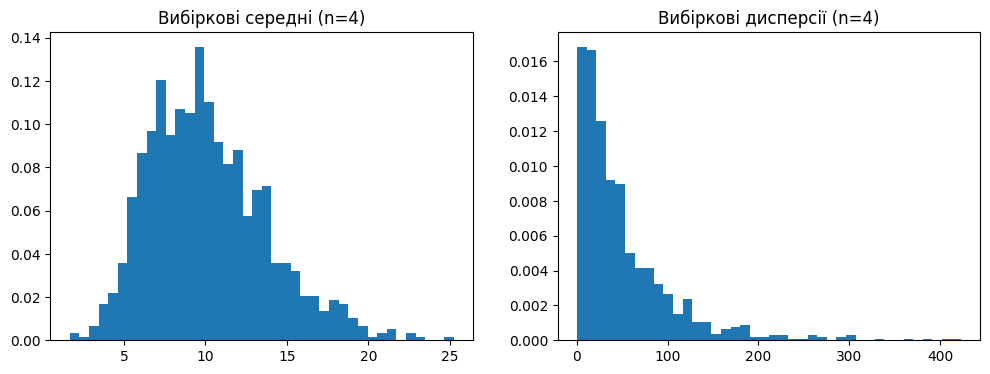

mean(x̄) = 10.135  mean(s²) = 50.981


In [4]:
b, n = 1000, 4
X = rng.gamma(k, theta, (b, n))
m4 = X.mean(axis=1)
v4 = X.var(axis=1, ddof=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(m4, bins=40, density=True)
ax[0].set_title("Вибіркові середні (n=4)")
ax[1].hist(v4, bins=40, density=True)
ax[1].set_title("Вибіркові дисперсії (n=4)")
plt.show()
print("mean(x̄) =", m4.mean().round(3), " mean(s²) =", v4.mean().round(3))

(в) Гістограма вибіркових середніх зосереджена навколо 10 (середнє $\bar x$ по 1000 вибірках ≈ 10.14), але має помітний правий хвіст. Вибіркові дисперсії в середньому ≈ 51 ≈ σ² = 50 (s² — незміщена оцінка), проте їх розподіл дуже асиметричний: при n = 4 окрема оцінка s² сильно розкидана.

(г) Для $X_i \sim \Gamma(2,5)$ незалежних: $E X_i = k\theta = 10$, $Var X_i = k\theta^2 = 50$.

$E\left(\frac{X_1+X_2+X_3+X_4}{4}\right) = \frac{1}{4}\cdot 4\cdot 10 = 10$,
$\quad Var\left(\frac{X_1+X_2+X_3+X_4}{4}\right) = \frac{1}{16}\cdot 4\cdot 50 = 12.5$.

In [5]:
E_m, V_m = mu, sigma**2 / n
print("E =", E_m, " Var =", V_m)

E = 10  Var = 12.500000000000002


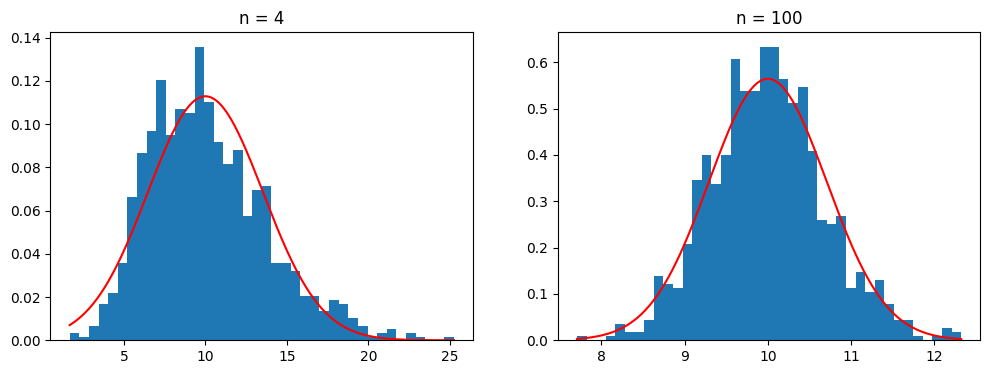

In [6]:
X100 = rng.gamma(k, theta, (b, 100)).mean(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, m, nn in zip(ax, [m4, X100], [4, 100]):
    a.hist(m, bins=40, density=True)
    x = np.linspace(m.min(), m.max(), 300)
    a.plot(x, stats.norm.pdf(x, mu, sigma / np.sqrt(nn)), "r")
    a.set_title(f"n = {nn}")
plt.show()

(д) При n = 4 гістограма середніх зміщена вправо (довший правий хвіст) і не повністю збігається з N(10, 12.5): середнє та дисперсія збігаються з теоретичними (E = 10, Var = 12.5 — це точні значення для будь-якого розподілу), але форма ні. Сума незалежних Γ(2,5) є Γ(8,5), тобто $\bar X\sim\Gamma(8,\,5/4)$ з коефіцієнтом асиметрії $2/\sqrt 8\approx0.71$ — для n=4 він ще помітний. Гістограма вибіркових дисперсій ще сильніше асиметрична.

При n = 100 за ЦГТ $\frac{\bar X-\mu}{\sigma/\sqrt n}\xrightarrow{d}N(0,1)$, тобто $\bar X\approx N(10,\,50/100)$: асиметрія спадає як $2/\sqrt{2n}\approx0.14$, розподіл стає вузьким і майже симетричним, і гістограма добре збігається з нормальною щільністю (другий графік).

## Частина 2. ML-оцінка параметра Бернуллі

In [7]:
r = df["Registration_Success"].values
D, p_val = lilliefors(r, dist="norm")
print("D =", round(D, 4), " p-value =", p_val)

D = 0.4571  p-value = 0.0009999999999998899


(а) $H_0$: дані походять з нормального розподілу (з невідомими μ, σ²); $H_1$: розподіл не нормальний.

Статистика $D=\sup_x|F_n(x)-\Phi(\frac{x-\bar x}{s})|=0.457$, p-value < 0.001 (0.001 — нижня межа таблиці statsmodels). $H_0$ відхиляємо: бінарні дані (лише 0 та 1) не можна апроксимувати нормальним розподілом, вони мають розподіл Бернуллі.

(б) $L(p) = \prod_{t=1}^{T} p^{r_t}(1-p)^{1-r_t} = p^{\sum r_t}(1-p)^{T-\sum r_t}$,
$\quad \ln L(p) = \sum_{t=1}^{T}\left(r_t\ln p + (1-r_t)\ln(1-p)\right)$.

In [8]:
def nll(p):
    return -np.sum(r * np.log(p) + (1 - r) * np.log(1 - p))

res = minimize(nll, x0=[0.5], bounds=[(1e-5, 1 - 1e-5)])
p_hat = res.x[0]
print("p_MLE =", p_hat, " x̄ =", r.mean())

p_MLE = 0.2719999710752206  x̄ = 0.272


Чисельна оцінка $\hat p_{MLE}\approx0.2720$ збігається з вибірковим середнім $\bar x = 68/250 = 0.272$. Це очікувано: з $\frac{d\ln L}{dp}=\frac{\sum r_t}{p}-\frac{T-\sum r_t}{1-p}=0$ отримуємо $\hat p=\frac{1}{T}\sum r_t=\bar x$.

In [9]:
B = stats.binom(20, p_hat)
print("P(X = 5)  =", round(B.pmf(5), 4))
print("P(X >= 8) =", round(B.sf(7), 4))
print("E =", round(20 * p_hat, 3), " P(X > E) =", round(B.sf(np.floor(20 * p_hat)), 4))

P(X = 5)  = 0.1974
P(X >= 8) = 0.1503
E = 5.44  P(X > E) = 0.4724


(в) $X\sim Bin(20,\ 0.272)$:
- $P(X=5)=\binom{20}{5}\hat p^5(1-\hat p)^{15}\approx0.197$;
- $P(X\ge8)=1-F(7)\approx0.150$;
- $E X=20\hat p=5.44$, $P(X>5.44)=P(X\ge6)=1-F(5)\approx0.472$.

## Частина 3. Тести для app_metrics.csv (α = 0.05)

In [10]:
alpha = 0.05
x = df["Session_Time"]
n = len(x)
t_stat = (x.mean() - 15) / (x.std() / np.sqrt(n))
print(f"x̄ = {x.mean():.4f}, s = {x.std():.4f}, n = {n}")
print(f"t = {t_stat:.4f}, t_крит = {stats.t.ppf(1 - alpha, n - 1):.4f}")
print(stats.ttest_1samp(x, 15, alternative="greater"))

x̄ = 16.5201, s = 5.0008, n = 250
t = 4.8063, t_крит = 1.6510
TtestResult(statistic=np.float64(4.806255093869331), pvalue=np.float64(1.3305773213989684e-06), df=np.int64(249))


(а) $H_0:\mu=15$, $H_1:\mu>15$ (правосторонній t-тест).

$t=\frac{\bar x-\mu_0}{s/\sqrt n}=\frac{16.520-15}{5.001/\sqrt{250}}=4.806$. Критична область: $t>t_{0.95,\,249}=1.651$. p-value = $1.3\cdot10^{-6}$.

$t$ потрапляє в критичну область, $H_0$ відхиляємо. Твердження менеджера підтверджується: середній час сесії статистично значуще перевищує 15 хв (оцінка ≈ 16.5 хв).

In [11]:
ios = df.loc[df.Platform == "iOS", "Revenue"]
andr = df.loc[df.Platform == "Android", "Revenue"]
v1, v2, n1, n2 = ios.var(), andr.var(), len(ios), len(andr)
se = np.sqrt(v1 / n1 + v2 / n2)
t_w = (ios.mean() - andr.mean()) / se
df_w = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
print(f"iOS: x̄ = {ios.mean():.2f}, s² = {v1:.2f}, n = {n1}")
print(f"Android: x̄ = {andr.mean():.2f}, s² = {v2:.2f}, n = {n2}")
print(f"t = {t_w:.4f}, df = {df_w:.2f}, t_крит = ±{stats.t.ppf(1 - alpha / 2, df_w):.4f}")
print(stats.ttest_ind(ios, andr, equal_var=False))

iOS: x̄ = 500.92, s² = 65010.51, n = 110
Android: x̄ = 393.51, s² = 17623.77, n = 140
t = 4.0118, df = 154.87, t_крит = ±1.9754
TtestResult(statistic=np.float64(4.0117508336823136), pvalue=np.float64(9.35453000437867e-05), df=np.float64(154.86944667828408))


(б) $H_0:\mu_{iOS}=\mu_{Android}$, $H_1:\mu_{iOS}\ne\mu_{Android}$.

$t=\frac{\bar x_1-\bar x_2}{\sqrt{s_1^2/n_1+s_2^2/n_2}}=\frac{500.92-393.51}{\sqrt{65010.51/110+17623.77/140}}=4.012$, ступені свободи за Велчем–Саттертуейтом $\nu\approx154.87$. Критична область: $|t|>t_{0.975,\,154.87}=1.975$. p-value = $9.4\cdot10^{-5}$.

$H_0$ відхиляємо. Середній чек iOS-користувачів значуще вищий, ніж Android (≈ 501 проти ≈ 394, різниця ≈ 107). Дисперсії сильно різняться (iOS має значно більший розкид), тому використання тесту Велча виправдане. Для бізнесу iOS-аудиторія приносить більше виручки на користувача.

In [12]:
r_p, p_p = stats.pearsonr(df["Page_Views"], df["Purchase_Amount"])
t_r = r_p * np.sqrt(n - 2) / np.sqrt(1 - r_p**2)
print(f"r = {r_p:.4f}, t = {t_r:.4f}, t_крит = ±{stats.t.ppf(1 - alpha / 2, n - 2):.4f}, p-value = {p_p:.3g}")

r = 0.9049, t = 33.4761, t_крит = ±1.9696, p-value = 5.74e-94


(в) $H_0:\rho=0$, $H_1:\rho\ne0$.

$t=\frac{r\sqrt{n-2}}{\sqrt{1-r^2}}=\frac{0.9049\sqrt{248}}{\sqrt{1-0.9049^2}}=33.48$. Критична область: $|t|>t_{0.975,\,248}=1.970$. p-value ≈ $6\cdot10^{-94}$.

$H_0$ відхиляємо, гіпотеза про відсутність зв'язку не підтверджується. Між кількістю переглядів і сумою покупки сильна додатна лінійна кореляція (r ≈ 0.90): користувачі, які переглядають більше сторінок, витрачають більше, тож метрики залученості є хорошим предиктором виручки.

In [13]:
p0 = 0.1
ph = df["Subscription"].mean()
z_p = (ph - p0) / np.sqrt(p0 * (1 - p0) / n)
print(f"p̂ = {ph:.4f}, z = {z_p:.4f}, z_крит = {stats.norm.ppf(1 - alpha):.4f}, p-value = {stats.norm.sf(z_p):.4f}")

p̂ = 0.1360, z = 1.8974, z_крит = 1.6449, p-value = 0.0289


(г) $H_0:p=0.1$, $H_1:p>0.1$.

$z=\frac{\hat p-p_0}{\sqrt{p_0(1-p_0)/n}}=\frac{0.136-0.1}{\sqrt{0.1\cdot0.9/250}}=1.897$. Критична область: $z>z_{0.95}=1.645$. p-value = 0.029.

$H_0$ відхиляємо. Частка користувачів з платною підпискою (13.6%) статистично значуще вища за 10%, хоча запас невеликий (p-value близьке до 0.05).

In [14]:
D_rev, p_rev = lilliefors(df["Revenue"], dist="norm")
print("D =", round(D_rev, 4), " p-value =", p_rev)

D = 0.1467  p-value = 0.0009999999999998899


(д) $H_0$: Revenue має нормальний розподіл; $H_1$: розподіл не нормальний.

$D=\sup_x|F_n(x)-\Phi(\frac{x-\bar x}{s})|=0.147$, p-value < 0.001, тому $H_0$ відхиляємо. Revenue не є нормальним (правосторонній хвіст, max ≈ 1654 при медіані ≈ 390). Однак для t-тестів у (б) це не критично: обсяги вибірок великі (110 і 140), і за ЦГТ розподіл вибіркових середніх близький до нормального, тож висновки t-тесту Велча залишаються приблизно коректними.

## Частина 4. Помилка 1-го роду, Монте-Карло

In [15]:
mu0, sd, n = 100, 5, 30
x = rng.normal(mu0, sd, n)
t_stat = (x.mean() - mu0) / (x.std(ddof=1) / np.sqrt(n))
t_crit = stats.t.ppf(0.975, n - 1)
print(f"x̄ = {x.mean():.4f}, s = {x.std(ddof=1):.4f}")
print(f"t = {t_stat:.4f}, критична область |t| > {t_crit:.4f}")
print("H0 відхиляємо" if abs(t_stat) > t_crit else "H0 не відхиляємо")

x̄ = 99.7861, s = 5.4287
t = -0.2158, критична область |t| > 2.0452
H0 не відхиляємо


(а) $H_0:\mu=100$, $H_1:\mu\ne100$. $t=\frac{\bar x-\mu_0}{s/\sqrt n}=\frac{99.786-100}{5.429/\sqrt{30}}=-0.216$. Критична область: $|t|>t_{0.975,\,29}=2.045$. $|t|<2.045$, тому $H_0$ не відхиляємо.

In [16]:
M = 5000
S = rng.normal(mu0, sd, (M, n))
p_i = (stats.ttest_1samp(S, mu0, axis=1).pvalue < 0.05).astype(int)
alpha_hat = p_i.mean()
print("α̂ =", alpha_hat, " SE =", round(np.sqrt(0.05 * 0.95 / M), 4))

α̂ = 0.0512  SE = 0.0031


(б) $\hat\alpha=0.0512$, що дуже близько до номінального α = 0.05. Різниця мала й пояснюється лише випадковістю моделювання: $\hat\alpha$ — частка успіхів у M незалежних випробуваннях Бернуллі з ймовірністю α, тому її стандартна похибка $\sqrt{0.05\cdot0.95/5000}\approx0.003$, а відхилення 0.0012 значно менше за неї. Так і має бути, бо всі припущення t-критерію виконано: вибірки незалежні, з нормального розподілу, і H0 справді істинна. Тоді $T\sim t_{29}$ точно, і $P(|T|>t_{0.975,29})=0.05$.

## Частина 5. Потужність тесту Ліліфорса проти t-розподілу

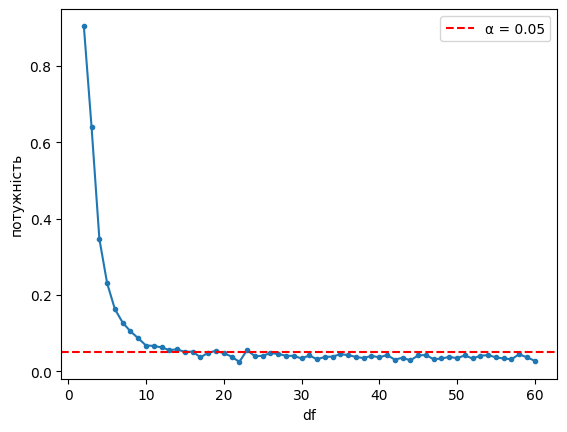

2     0.905
3     0.639
4     0.347
5     0.231
10    0.068
20    0.048
30    0.034
60    0.028
dtype: float64


In [17]:
M, n = 1000, 80
dfs = np.arange(2, 61)
power = []
for d in dfs:
    rej = sum(lilliefors(rng.standard_t(d, n), dist="norm")[1] < 0.05 for _ in range(M))
    power.append(rej / M)

plt.plot(dfs, power, "o-", ms=3)
plt.axhline(0.05, color="r", ls="--", label="α = 0.05")
plt.xlabel("df"); plt.ylabel("потужність"); plt.legend()
plt.show()
print(pd.Series(power, index=dfs)[[2, 3, 4, 5, 10, 20, 30, 60]])

Дані генеруються з t-розподілу, тобто $H_0$ (нормальність) хибна. Тому частка відхилень $\frac{1}{M}\sum p_i$ є емпіричною оцінкою ймовірності правильно відхилити $H_0$, тобто потужності $1-\beta$.

При малих df потужність висока (≈ 0.91 при df = 2, 0.64 при df = 3), бо хвости дуже важкі. Вона швидко падає: при df ≥ 10 тест майже не відрізняє t-розподіл від нормального, і потужність стає порядку α. Це очікувано, бо при df → ∞ t-розподіл збігається до нормального, і $H_1$ фактично наближається до $H_0$. Потужність при великих df навіть трохи менша за 0.05, оскільки p-value з таблиці statsmodels (`pvalmethod="table"`) консервативні: реальний розмір тесту при n = 80 ≈ 0.03.

Висновок: при n = 80 тест Ліліфорса надійно ловить лише сильні відхилення від нормальності (df ≤ 4–5). Для df ≳ 10 він практично нечутливий, тож відсутність відхилення $H_0$ не доводить нормальність. Для слабших відхилень потрібні більші вибірки або потужніші тести (наприклад, Шапіро–Вілка).